# SentimentScope: Sentiment Analysis using Transformers!

## Introduction

In this notebook we train a transformer model **from scratch** to perform sentiment analysis on the IMDB dataset. As a Machine Learning Engineer at CineScope, the goal is to classify movie reviews as positive (`1`) or negative (`0`) so the recommendation system can take user sentiment into account.

Learning objectives:

* Load, explore, and prepare a text dataset for training a transformer model using PyTorch.
* Customize the architecture of the transformer model for a classification task.
* Train and test a transformer model on the IMDB dataset.

## Project Outline

1. [Load, Explore, and Prepare the Dataset](#Load,-Explore,-and-Prepare-the-Dataset)
2. [Implement a DataLoader in PyTorch](#Implement-a-DataLoader-in-PyTorch)
3. [Customize the Transformer Architecture](#Customize-the-Transformer-Architecture)
4. [Implement Accuracy Calculation Method](#Implement-Accuracy-Calculation-Method)
5. [Train the Model](#Train-the-Model)
6. [Test the Model](#Test-the-Model)
7. [Save the Checkpoint and Run Inference](#Save-the-Checkpoint-and-Run-Inference)
8. [Conclusion](#Conclusion)

## Data Description

The dataset is the [IMDB Large Movie Review dataset](https://ai.stanford.edu/~amaas/data/sentiment/), provided as `aclImdb_v1.tar.gz`:

```
aclImdb/
├── train/
│   ├── pos/    # Positive reviews for training
│   ├── neg/    # Negative reviews for training
│   ├── unsup/  # Unsupervised data (not used in this project)
├── test/
│   ├── pos/    # Positive reviews for testing
│   ├── neg/    # Negative reviews for testing
```

## Load, Explore, and Prepare the Dataset

### 1. Load the Dataset

In [1]:
import os
import pandas as pd

# Unpack the dataset (the unused `unsup` folder is skipped to save time and disk space)
if not os.path.isdir('aclImdb'):
    !tar -xzf aclImdb_v1.tar.gz --exclude="aclImdb/train/unsup"

In [2]:
# Define paths to dataset
train_pos_path = os.path.join('aclImdb', 'train', 'pos')  # Positive reviews from the training set
train_neg_path = os.path.join('aclImdb', 'train', 'neg')  # Negative reviews from the training set
test_pos_path = os.path.join('aclImdb', 'test', 'pos')    # Positive reviews from the test set
test_neg_path = os.path.join('aclImdb', 'test', 'neg')    # Negative reviews from the test set

In [3]:
def load_dataset(folder):
    """
    Reads all text files in the specified folder and returns their content as a list.

    Args:
        folder (str): Path to the folder containing text files.

    Returns:
        list: A list of strings, where each string is the content of a text file.
    """
    reviews = []
    # Sort the file names so the loading order is deterministic across machines
    for file_name in sorted(os.listdir(folder)):
        if not file_name.endswith('.txt'):
            continue
        with open(os.path.join(folder, file_name), 'r', encoding='utf-8') as f:
            reviews.append(f.read())
    return reviews

In [4]:
# Load training and testing data
train_pos = load_dataset(train_pos_path)
train_neg = load_dataset(train_neg_path)
test_pos = load_dataset(test_pos_path)
test_neg = load_dataset(test_neg_path)

In [5]:
# Create DataFrames
train_df = pd.DataFrame({
    'review': train_pos + train_neg,
    'label': [1] * len(train_pos) + [0] * len(train_neg)
})

test_df = pd.DataFrame({
    'review': test_pos + test_neg,
    'label': [1] * len(test_pos) + [0] * len(test_neg)
})

print(train_df.head())

                                              review  label
0  Bromwell High is a cartoon comedy. It ran at t...      1
1  Homelessness (or Houselessness as George Carli...      1
2  Brilliant over-acting by Lesley Ann Warren. Be...      1
3  This is easily the most underrated film inn th...      1
4  This is not the typical Mel Brooks film. It wa...      1


In [6]:
# Assert that both datasets have the expected number of rows
assert train_df.shape[0] == 25000, "Training dataset does not have 25000 rows."
assert test_df.shape[0] == 25000, "Testing dataset does not have 25000 rows."

# Assert that both datasets have exactly two columns
assert train_df.shape[1] == 2, "Training dataset does not have exactly 2 columns."
assert test_df.shape[1] == 2, "Testing dataset does not have exactly 2 columns."

### 2. Explore the Dataset

We look at the overall structure, the label balance, the review lengths, and a few raw examples.

In [7]:
# Dataset overview
train_df.info()
print()
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   review  25000 non-null  str  
 1   label   25000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 390.8 KB

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   review  25000 non-null  str  
 1   label   25000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 390.8 KB


In [8]:
# Descriptive statistics of review lengths (characters and words)
for df in (train_df, test_df):
    df['char_count'] = df['review'].str.len()
    df['word_count'] = df['review'].str.split().str.len()

print("Train set:")
display(train_df[['label', 'char_count', 'word_count']].describe().round(2))
print("Test set:")
display(test_df[['label', 'char_count', 'word_count']].describe().round(2))

print("Word count by label (train):")
display(train_df.groupby('label')['word_count'].describe().round(2))

print("Missing values (train):", train_df['review'].isna().sum(),
      "| Duplicate reviews (train):", train_df['review'].duplicated().sum())

Train set:


,label,char_count,word_count
count,25000.0,25000.00,25000.00
mean,0.5,1325.07,233.79
std,0.5,1003.13,173.73
min,0.0,52.00,10.00
25%,0.0,702.00,127.00
50%,0.5,979.00,174.00
75%,1.0,1614.00,284.00
max,1.0,13704.00,2470.00


Test set:


,label,char_count,word_count
count,25000.0,25000.00,25000.00
mean,0.5,1293.79,228.53
std,0.5,975.91,168.88
min,0.0,32.00,4.00
25%,0.0,696.00,126.00
50%,0.5,962.00,172.00
75%,1.0,1572.00,277.00
max,1.0,12988.00,2278.00


Word count by label (train):


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,12500.0,230.87,166.66,10.0,128.0,174.0,278.0,1522.0
1,12500.0,236.71,180.49,12.0,125.0,174.0,291.0,2470.0


Missing values (train): 0 | Duplicate reviews (train): 96


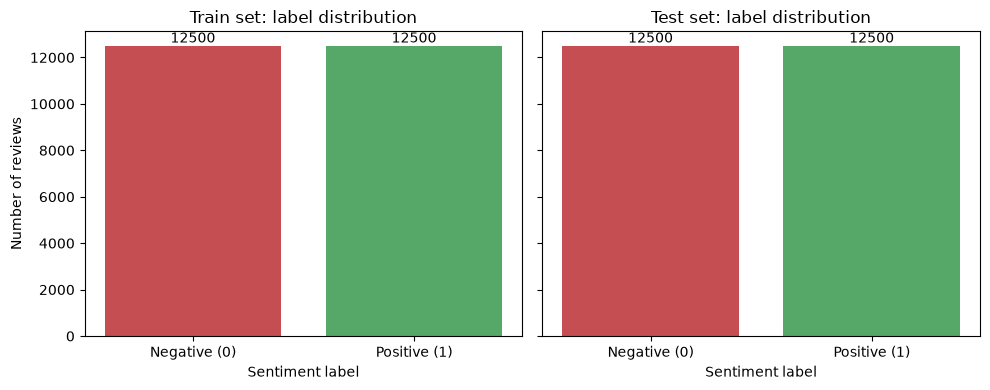

In [9]:
import matplotlib.pyplot as plt

# Label distribution
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, df) in zip(axes, [('Train', train_df), ('Test', test_df)]):
    counts = df['label'].value_counts().sort_index()
    bars = ax.bar(['Negative (0)', 'Positive (1)'], counts.values, color=['#c44e52', '#55a868'])
    ax.bar_label(bars)
    ax.set_title(f'{name} set: label distribution')
    ax.set_xlabel('Sentiment label')
axes[0].set_ylabel('Number of reviews')
plt.tight_layout()
plt.show()

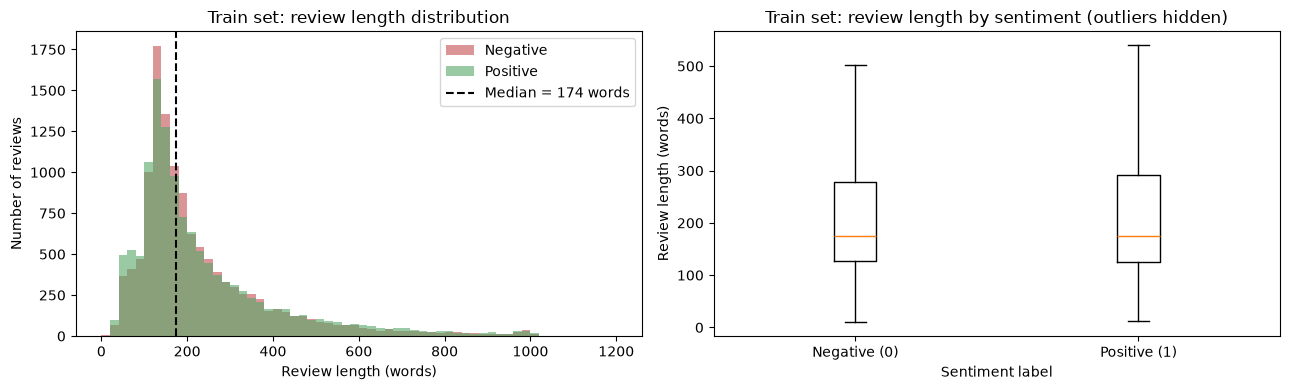

In [10]:
# Review length distribution (words), split by sentiment
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for label, name, color in [(0, 'Negative', '#c44e52'), (1, 'Positive', '#55a868')]:
    axes[0].hist(train_df.loc[train_df['label'] == label, 'word_count'],
                 bins=60, range=(0, 1200), alpha=0.6, label=name, color=color)
axes[0].axvline(train_df['word_count'].median(), color='black', linestyle='--',
                label=f"Median = {train_df['word_count'].median():.0f} words")
axes[0].set_title('Train set: review length distribution')
axes[0].set_xlabel('Review length (words)')
axes[0].set_ylabel('Number of reviews')
axes[0].legend()

axes[1].boxplot([train_df.loc[train_df['label'] == 0, 'word_count'],
                 train_df.loc[train_df['label'] == 1, 'word_count']],
                showfliers=False)
axes[1].set_xticks([1, 2], ['Negative (0)', 'Positive (1)'])
axes[1].set_title('Train set: review length by sentiment (outliers hidden)')
axes[1].set_xlabel('Sentiment label')
axes[1].set_ylabel('Review length (words)')

plt.tight_layout()
plt.show()

In [11]:
# Sample reviews
for label, name in [(1, 'POSITIVE'), (0, 'NEGATIVE')]:
    print(f"--- {name} ---")
    for review in train_df.loc[train_df['label'] == label, 'review'].sample(2, random_state=0):
        print(review[:400] + ('...' if len(review) > 400 else ''))
        print()

--- POSITIVE ---
"Perhaps we can arrange a meet. " "Where are you now? " "I'm sitting in my office. " "I doubt that. " "Why would you doubt that? " "If you were in your office right now we'd be having this conversation face-to-face. "<br /><br />Bourne remains street tough, and elusive. Only his inhuman resilience leads the film a little too far into fantasy. Conversation is macho, to the point with only shards of...

This movie is horrible- in a 'so bad it's good' kind of way.<br /><br />The storyline is rehashed from so many other films of this kind, that I'm not going to even bother describing it. It's a sword/sorcery picture, has a kid hoping to realize how important he is in this world, has a "nomadic" adventurer, an evil aide/sorcerer, a princess, a hairy creature....you get the point.<br /><br />The firs...

--- NEGATIVE ---
So there's an old security guard and a guy who dies and then there's KEVIN, the world's biggest wuss. Kevin wants to impress his incredibly insensitive, bra

**Observations**

* Both splits are perfectly balanced (12,500 positive / 12,500 negative), so accuracy is a meaningful metric and a random model should score about 50%.
* Review lengths are heavily right-skewed: the median review is a bit under 200 words, but the tail runs past 1,000 words. Positive and negative reviews have very similar length distributions, so length alone is not a useful signal.
* Most reviews are longer than the 128-token context we use below, so the model only sees the beginning of most reviews.
* The raw text contains HTML line breaks (`<br />`), which we remove below so they do not waste tokens.

### 3. Prepare the Dataset

First a light cleaning step (strip the HTML line breaks), then we shuffle and split the training data into training and validation subsets.

In [12]:
# Clean the text: remove HTML line breaks and collapse repeated whitespace
for df in (train_df, test_df):
    df['review'] = (df['review']
                    .str.replace(r'<br\s*/?>', ' ', regex=True)
                    .str.replace(r'\s+', ' ', regex=True)
                    .str.strip())
    df.drop(columns=['char_count', 'word_count'], inplace=True)

# Split train data into training and validation sets manually
train_size = int(0.9 * len(train_df))
# Shuffle the dataset
shuffled_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
train_data = shuffled_df.iloc[:train_size]
val_data = shuffled_df.iloc[train_size:]

print("Train label balance:", train_data['label'].mean().round(4))
print("Validation label balance:", val_data['label'].mean().round(4))

Train label balance: 0.5001
Validation label balance: 0.4988


### 4. Testing the Tokenizer

We use the `bert-base-uncased` subword tokenizer (only the tokenizer, not the pretrained model weights).

In [13]:
from transformers import AutoTokenizer

# Initialize tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

C:\Users\ragav\.venvs\sentimentscope\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\ragav\.venvs\sentimentscope\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ragav\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [14]:
# Take sample inputs from the dataset
sample_texts = train_data['review'].sample(3, random_state=42).tolist()

# Tokenize sample inputs
tokenized_samples = tokenizer(sample_texts, truncation=True, padding="max_length", max_length=128, return_tensors="pt")

print(tokenized_samples)
print(tokenizer.convert_ids_to_tokens(tokenized_samples['input_ids'][0][:20]))

{'input_ids': tensor([[  101,  2348,  1996,  3185,  2003,  4415,  6052,  1010,  9501,  2064,
          2145,  4089,  6709,  2007,  1996, 24525,  1997,  5292, 21112,  2015,
         18396,  1999,  2023, 27768,  1998,  2200,  6057,  2104, 16168,  6925,
          1012, 18396,  9590,  2114,  4895, 18824,  2135, 10238,  1999,  2093,
          2367,  5535,  1024,  1996,  2962,  2287,  1010,  1996,  3142,  2287,
          1010,  1998,  1996,  5549,  2078,  2287,  1010,  2652,  2471,  1996,
          2168,  2839,  2007,  2074,  1037,  2689,  1997, 17363,  2000,  2393,
          2149,  6709,  1996,  2367,  1000,  5535,  1000,  1012,  1999,  2023,
          3185,  2057,  2156,  2028,  1997,  1996,  5700, 21699, 20818,  1997,
          1996,  1000,  5430,  2386,  1000, 12991, 13874,  1010,  2040,  5222,
          2010,  2293,  2025,  2011,  7472,  2021,  2011, 26128,  2486,  1010,
          2004,  2092,  2004,  1037,  6057,  9792,  2006,  3142,  5580,  2401,
         29469,  2389,  4337,  1010,  

## Implement a DataLoader in PyTorch

### 1. Define a Custom Dataset Class

In [15]:
import torch
from torch.utils.data import Dataset
MAX_LENGTH = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(42)

Using device: cuda


In [16]:
class IMDBDataset(Dataset):
    """
    A custom PyTorch Dataset for the IMDB dataset.

    This class preprocesses text data using a tokenizer and returns tokenized inputs
    along with their corresponding labels for sentiment analysis.

    Attributes:
        data (pd.DataFrame): A DataFrame containing text and label columns.
        tokenizer (transformers.PreTrainedTokenizer): The tokenizer used for preprocessing text.
        max_length (int): Maximum length for tokenized sequences.
    """
    def __init__(self, data, tokenizer, max_length=MAX_LENGTH):
        """
        Initialize the dataset.

        Args:
            data (pd.DataFrame): A DataFrame with columns `review` (text) and `label` (target).
            tokenizer (transformers.PreTrainedTokenizer): The tokenizer to preprocess the text.
            max_length (int, optional): Maximum token sequence length. Defaults to 128.
        """
        # Reset the index so positional lookups work on shuffled / sliced DataFrames
        self.data = data.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        """
        Return the total number of samples in the dataset.

        Returns:
            int: Number of samples.
        """
        return len(self.data)

    def __getitem__(self, idx):
        """
        Retrieve a single data point by index and preprocess it.

        Args:
            idx (int): Index of the data point to retrieve.

        Returns:
            torch.Tensor: Tokenized input IDs for the text.
            int: Label corresponding to the text.
        """
        row = self.data.iloc[idx]
        encoding = self.tokenizer(
            row['review'],
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        input_ids = encoding['input_ids'].squeeze(0)  # (1, max_length) -> (max_length,)
        label = int(row['label'])
        return input_ids, label

### 2. Initialize the Dataset

In [17]:
# Initialize the datasets
train_dataset = IMDBDataset(train_data, tokenizer)
val_dataset = IMDBDataset(val_data, tokenizer)
test_dataset = IMDBDataset(test_df, tokenizer)

### 3. Create a DataLoader

In [18]:
from torch.utils.data import DataLoader

# Define batch size
BATCH_SIZE = 32

# Create DataLoader instances
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [19]:
assert len(train_dataset) == 22500, "Train dataset length mismatch!"
assert len(val_dataset) == 2500, "Validation dataset length mismatch!"
assert len(test_dataset) == 25000, "Test dataset length mismatch!"

import numpy as np

# Check the first item in the train dataset
input_ids, label = train_dataset[0]
assert isinstance(input_ids, torch.Tensor), "Input IDs should be a torch.Tensor!"
assert isinstance(label, (int, np.integer)), "Label should be an integer or int-like!"

# Ensure the input IDs tensor has the correct shape
assert input_ids.shape[0] == train_dataset.max_length, "Input IDs tensor has incorrect length!"

## Customize the Transformer Architecture

### 1. Config Dictionary

In [20]:
config = {
    "vocabulary_size": tokenizer.vocab_size,  # e.g., ~30522 for bert-base-uncased
    "num_classes": 2,                         # binary classification (pos/neg)
    "d_embed": 128,
    "context_size": MAX_LENGTH,
    "layers_num": 4,
    "heads_num": 4,
    "head_size": 32,  # 4 heads * 32 = 128 -> matches d_embed
    "dropout_rate": 0.1,
    "use_bias": True
}

### 2. Class Definitions

#### AttentionHead

In [21]:
import torch.nn as nn
import math

class AttentionHead(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.Q_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.K_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])
        self.V_weights = nn.Linear(config["d_embed"], config["head_size"], bias=config["use_bias"])

        self.dropout = nn.Dropout(config["dropout_rate"])

        casual_attention_mask = torch.tril(torch.ones(config["context_size"], config["context_size"]))
        self.register_buffer('casual_attention_mask', casual_attention_mask)

    def forward(self, input):
        batch_size, tokens_num, d_embed = input.shape
        Q = self.Q_weights(input)  # (B, T, head_size)
        K = self.K_weights(input)  # (B, T, head_size)
        V = self.V_weights(input)  # (B, T, head_size)

        # Q @ K^T => (B, T, T)
        attention_scores = Q @ K.transpose(1, 2)

        # Casual Mask
        attention_scores = attention_scores.masked_fill(
            self.casual_attention_mask[:tokens_num, :tokens_num] == 0,
            float('-inf')
        )
        attention_scores = attention_scores / math.sqrt(K.shape[-1])
        attention_scores = torch.softmax(attention_scores, dim=-1)
        attention_scores = self.dropout(attention_scores)

        return attention_scores @ V

In [22]:
# Instantiate the AttentionHead
attention_head = AttentionHead(config).to(device)

# Create a dummy input of shape (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
attention_output = attention_head(dummy_input)
print("AttentionHead output shape:", attention_output.shape)

AttentionHead output shape: torch.Size([32, 128, 32])


#### MultiHeadAttention

In [23]:
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        heads_list = [AttentionHead(config) for _ in range(config["heads_num"])]
        self.heads = nn.ModuleList(heads_list)

        self.linear = nn.Linear(config["heads_num"] * config["head_size"], config["d_embed"])
        self.dropout = nn.Dropout(config["dropout_rate"])

    def forward(self, input):
        heads_outputs = [head(input) for head in self.heads]
        x = torch.cat(heads_outputs, dim=-1)  # (B, T, heads_num * head_size)
        x = self.linear(x)                   # (B, T, d_embed)
        x = self.dropout(x)
        return x

# Instantiate MultiHeadAttention
multi_head_attention = MultiHeadAttention(config).to(device)

# Same dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
mha_output = multi_head_attention(dummy_input)
print("MultiHeadAttention output shape:", mha_output.shape)

MultiHeadAttention output shape: torch.Size([32, 128, 128])


#### FeedForward

In [24]:
class FeedForward(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.linear_layers = nn.Sequential(
            nn.Linear(config["d_embed"], 4 * config["d_embed"]),
            nn.GELU(),
            nn.Linear(4 * config["d_embed"], config["d_embed"]),
            nn.Dropout(config["dropout_rate"])
        )

    def forward(self, input):
        return self.linear_layers(input)

# Instantiate FeedForward
feed_forward = FeedForward(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
ff_output = feed_forward(dummy_input)
print("FeedForward output shape:", ff_output.shape)

FeedForward output shape: torch.Size([32, 128, 128])


#### Block

In [25]:
class Block(nn.Module):
    def __init__(self, config):
        super().__init__()

        self.multi_head = MultiHeadAttention(config)
        self.layer_norm_1 = nn.LayerNorm(config["d_embed"])

        self.feed_forward = FeedForward(config)
        self.layer_norm_2 = nn.LayerNorm(config["d_embed"])

    def forward(self, input):
        x = input
        x = x + self.multi_head(self.layer_norm_1(x))
        x = x + self.feed_forward(self.layer_norm_2(x))
        return x

# Instantiate a single Block
block = Block(config).to(device)

# Dummy input: (32, 128, 128)
dummy_input = torch.randn(BATCH_SIZE, config["context_size"], config["d_embed"]).to(device)

# Forward pass
block_output = block(dummy_input)
print("Block output shape:", block_output.shape)

Block output shape:

 torch.Size([32, 128, 128])


#### DemoGPT

Two changes adapt the generation-style transformer to binary classification:

1. **Classification head**: a linear layer mapping `d_embed` to `num_classes`, replacing the vocabulary-sized output layer.
2. **Mean pooling**: the per-token embeddings `(B, T, d_embed)` are averaged over the time dimension into one vector per review `(B, d_embed)` before the head.

The model returns logits; `softmax` over them gives the class probabilities (`CrossEntropyLoss` applies it internally during training, and the inference helper at the end applies it explicitly).

In [26]:
class DemoGPT(nn.Module):
    def __init__(self, config):
        """
        Initialize the DemoGPT class with configuration parameters.

        Args:
        - config (dict): Configuration dictionary with the following keys:
            - "vocabulary_size": Size of the vocabulary.
            - "d_embed": Dimensionality of the embedding vectors.
            - "context_size": Maximum sequence length (context size).
            - "layers_num": Number of transformer layers.
            - "num_classes": Number of output classes (2 for binary classification).
        """
        super().__init__()
        # Token embedding layer: Maps token indices to embedding vectors.
        self.token_embedding_layer = nn.Embedding(config["vocabulary_size"], config["d_embed"])

        # Positional embedding layer: Adds positional information to the embeddings.
        self.positional_embedding_layer = nn.Embedding(config["context_size"], config["d_embed"])

        # Transformer layers: Stacked sequence of transformer blocks.
        blocks = [Block(config) for _ in range(config["layers_num"])]
        self.layers = nn.Sequential(*blocks)

        # Layer normalization: Applied to stabilize training.
        self.layer_norm = nn.LayerNorm(config["d_embed"])

        # Classification output layer: Maps pooled embeddings to class logits.
        self.classifier = nn.Linear(config["d_embed"], config["num_classes"], bias=False)

    def forward(self, token_ids):
        """
        Forward pass of the model.

        Args:
        - token_ids (torch.Tensor): Input token indices of shape (B, T),
                                    where B is the batch size, and T is the sequence length.

        Returns:
        - logits (torch.Tensor): Output logits of shape (B, num_classes).
        """
        batch_size, tokens_num = token_ids.shape

        # Step 1: Create embeddings for tokens and their positions
        x = self.token_embedding_layer(token_ids)  # Shape: (B, T, d_embed)
        positions = torch.arange(tokens_num, device=token_ids.device)  # Shape: (T,)
        pos_embed = self.positional_embedding_layer(positions)  # Shape: (T, d_embed)
        x = x + pos_embed.unsqueeze(0)  # Add positional embeddings to token embeddings

        # Step 2: Pass embeddings through transformer layers
        x = self.layers(x)  # Shape: (B, T, d_embed)
        x = self.layer_norm(x)  # Normalize across the feature dimension

        # Step 3: Apply mean pooling across the time dimension
        x = torch.mean(x, dim=1)  # Shape: (B, d_embed)

        # Step 4: Generate logits for classification
        logits = self.classifier(x)  # Shape: (B, num_classes)

        return logits

In [27]:
# Instantiate the model
demo_gpt = DemoGPT(config).to(device)

# Suppose we have a batch of size 32, each with a sequence length of 128
dummy_token_ids = torch.randint(
    0, config["vocabulary_size"],
    (BATCH_SIZE, config["context_size"])
).to(device)

# Forward pass
logits = demo_gpt(dummy_token_ids)

print("DemoGPT output shape:", logits.shape)
print("Logits sample:\n", logits[:2])  # Print first two examples' logits
print("Probabilities sample:\n", torch.softmax(logits[:2], dim=-1))
print("Trainable parameters:", sum(p.numel() for p in demo_gpt.parameters() if p.requires_grad))

DemoGPT output shape: torch.Size([32, 2])
Logits sample:
 

tensor([[-0.1151,  0.0131],
        [-0.1358, -0.0651]], device='cuda:0', grad_fn=<SliceBackward0>)
Probabilities sample:
 tensor([[0.4680, 0.5320],
        [0.4823, 0.5177]], device='cuda:0', grad_fn=<SoftmaxBackward0>)
Trainable parameters: 4716800


In [28]:
# Assert that the number of logits matches the number of classes
assert logits.size(1) == config["num_classes"], (
    f"Expected number of classes {config['num_classes']}, "
    f"but got {logits.size(1)}"
)

# Assert that the batch size of the output matches the input batch size
assert logits.size(0) == BATCH_SIZE, (
    f"Expected batch size {BATCH_SIZE}, "
    f"but got {logits.size(0)}"
)

## Implement Accuracy Calculation Method

In [29]:
def calculate_accuracy(model, data_loader, device):
    """
    Calculate the accuracy of the model on the validation dataset.

    Args:
        model (torch.nn.Module): The trained transformer model.
        data_loader (torch.utils.data.DataLoader): DataLoader for the validation dataset.
        device (torch.device): Device to run the model (e.g., 'cuda' or 'cpu').

    Returns:
        float: Validation accuracy as a percentage.
    """
    model.eval()
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for input_ids, labels in data_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)

            logits = model(input_ids)
            predictions = torch.argmax(logits, dim=1)

            total_correct += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    accuracy = (total_correct / total_samples) * 100
    return accuracy

In [30]:
model = DemoGPT(config).to(device)

validation_accuracy = calculate_accuracy(model, val_loader, device)
print(f"Validation Accuracy: {validation_accuracy:.2f}%")

Validation Accuracy: 51.56%


As expected, the untrained model is close to 50% (random guessing on a balanced dataset).

## Train the Model

Each epoch is one full pass over the 22,500 training reviews. After every epoch we measure validation loss and accuracy, and keep a copy of the weights from the epoch with the best validation accuracy so that later overfitting does not hurt the final model.

In [31]:
def calculate_loss(model, data_loader, criterion, device):
    """Average cross-entropy loss of the model over a data loader."""
    model.eval()
    total_loss = 0.0
    total_samples = 0

    with torch.no_grad():
        for input_ids, labels in data_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)
            loss = criterion(model(input_ids), labels)
            total_loss += loss.item() * labels.size(0)
            total_samples += labels.size(0)

    return total_loss / total_samples

In [32]:
import copy
import time
import torch.optim as optim

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training parameters
EPOCHS = 5
LEARNING_RATE = 3e-4

# Initialize model, loss, and optimizer
torch.manual_seed(42)
model = DemoGPT(config).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)

history = {"train_loss": [], "val_loss": [], "val_accuracy": []}
best_val_accuracy = 0.0
best_epoch = 0
best_state_dict = None

# Training loop
for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    epoch_loss = 0.0
    start_time = time.time()

    for step, (input_ids, labels) in enumerate(train_loader):
        # Move data to device
        input_ids = input_ids.to(device)
        labels = labels.to(device)

        # Forward pass
        logits = model(input_ids)

        # Calculate loss
        loss = criterion(logits, labels)

        # Set gradients to zero
        optimizer.zero_grad()

        # Backward pass
        loss.backward()

        # Step the optimizer
        optimizer.step()

        running_loss += loss.item()
        epoch_loss += loss.item()

        # Log training progress
        if (step + 1) % 100 == 0:
            print(f"Epoch [{epoch+1}/{EPOCHS}], Step [{step+1}/{len(train_loader)}], "
                  f"Loss: {running_loss/100:.4f}")
            running_loss = 0.0

    # Evaluate validation loss and accuracy
    train_loss = epoch_loss / len(train_loader)
    val_loss = calculate_loss(model, val_loader, criterion, device)
    val_accuracy = calculate_accuracy(model, val_loader, device)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    print(f"Epoch {epoch+1} - Train Loss: {train_loss:.4f} - Validation Loss: {val_loss:.4f} - "
          f"Validation Accuracy: {val_accuracy:.2f}% - Time: {time.time() - start_time:.0f}s")

    # Keep the weights of the best epoch so far
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1
        best_state_dict = copy.deepcopy(model.state_dict())

# Restore the best weights
model.load_state_dict(best_state_dict)
print(f"Best validation accuracy: {best_val_accuracy:.2f}% (epoch {best_epoch})")

Epoch [1/5], Step [100/704], Loss: 0.6932


Epoch [1/5], Step [200/704], Loss: 0.6521


Epoch [1/5], Step [300/704], Loss: 0.6458


Epoch [1/5], Step [400/704], Loss: 0.6286


Epoch [1/5], Step [500/704], Loss: 0.6087


...

Epoch [5/5], Step [400/704], Loss: 0.2872


Epoch [5/5], Step [500/704], Loss: 0.2978


Epoch [5/5], Step [600/704], Loss: 0.3107


Epoch [5/5], Step [700/704], Loss: 0.3085


Epoch 5 - Train Loss: 0.3088 - Validation Loss: 0.4683 - Validation Accuracy: 79.52% - Time: 286s
Best validation accuracy: 80.04% (epoch 4)


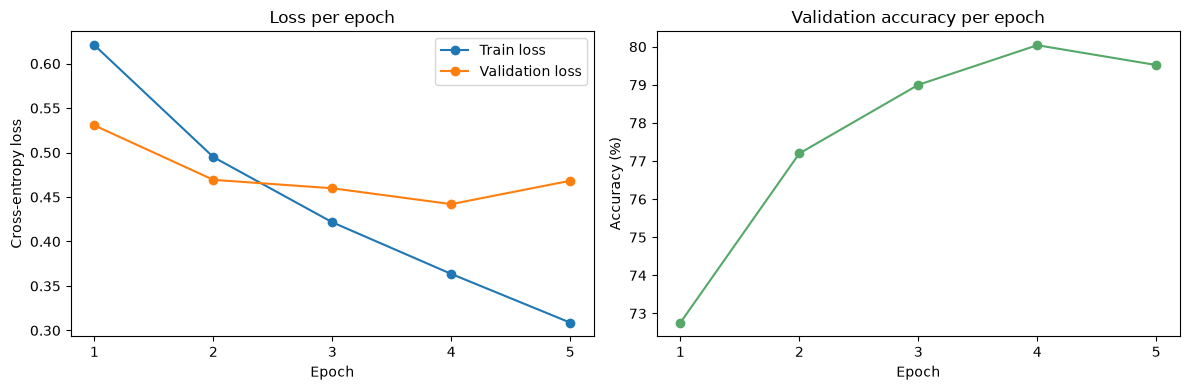

In [33]:
# Training curves
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], marker='o', label='Train loss')
axes[0].plot(epochs_range, history["val_loss"], marker='o', label='Validation loss')
axes[0].set_title('Loss per epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].set_xticks(list(epochs_range))
axes[0].legend()

axes[1].plot(epochs_range, history["val_accuracy"], marker='o', color='#55a868')
axes[1].set_title('Validation accuracy per epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_xticks(list(epochs_range))

plt.tight_layout()
plt.show()

## Test the Model

We evaluate the best-validation weights on the 25,000 held-out test reviews. The project goal is a test accuracy above 75%.

In [34]:
# Calculate the accuracy of the model over the test set using the calculate_accuracy() function
test_accuracy = calculate_accuracy(model, test_loader, device)
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 78.04%


## Save the Checkpoint and Run Inference

The checkpoint stores the weights together with the config needed to rebuild the model. `load_model()` restores it, and `predict_sentiment()` classifies a batch of raw review strings and returns the probability of each class.

In [35]:
CHECKPOINT_PATH = "sentimentscope_checkpoint.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "config": config,
    "tokenizer_name": "bert-base-uncased",
    "max_length": MAX_LENGTH,
    "best_epoch": best_epoch,
    "val_accuracy": best_val_accuracy,
    "test_accuracy": test_accuracy,
}, CHECKPOINT_PATH)
print(f"Saved checkpoint to {CHECKPOINT_PATH} ({os.path.getsize(CHECKPOINT_PATH) / 1e6:.1f} MB)")

Saved checkpoint to sentimentscope_checkpoint.pt (20.0 MB)


In [36]:
def load_model(checkpoint_path, device):
    """
    Rebuild the model and tokenizer from a saved checkpoint.

    Returns:
        tuple: (model in eval mode, tokenizer, max_length)
    """
    checkpoint = torch.load(checkpoint_path, map_location=device)
    loaded_model = DemoGPT(checkpoint["config"]).to(device)
    loaded_model.load_state_dict(checkpoint["model_state_dict"])
    loaded_model.eval()
    loaded_tokenizer = AutoTokenizer.from_pretrained(checkpoint["tokenizer_name"])
    return loaded_model, loaded_tokenizer, checkpoint["max_length"]


def predict_sentiment(texts, model, tokenizer, device, max_length=MAX_LENGTH):
    """
    Classify a batch of raw review strings.

    Args:
        texts (list[str]): Reviews to classify.

    Returns:
        pd.DataFrame: One row per review with the predicted sentiment and class probabilities.
    """
    input_ids = tokenizer(texts, truncation=True, padding="max_length",
                          max_length=max_length, return_tensors="pt")["input_ids"].to(device)
    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(input_ids), dim=-1).cpu()

    return pd.DataFrame({
        "review": texts,
        "sentiment": ["positive" if p == 1 else "negative" for p in probabilities.argmax(dim=1).tolist()],
        "p_negative": probabilities[:, 0].numpy().round(4),
        "p_positive": probabilities[:, 1].numpy().round(4),
    })

In [37]:
loaded_model, loaded_tokenizer, loaded_max_length = load_model(CHECKPOINT_PATH, device)

sample_reviews = [
    "The movie was a rollercoaster of emotions, and I loved every moment of it!",
    "The plot was predictable, and the acting was subpar. A waste of time.",
    "A beautiful, moving film with wonderful performances. Highly recommended.",
    "Boring and far too long. I nearly fell asleep halfway through.",
]

predict_sentiment(sample_reviews, loaded_model, loaded_tokenizer, device, loaded_max_length)

,review,sentiment,p_negative,p_positive
0,"The movie was a rollercoaster of emotions, and...",positive,0.0081,0.9919
1,"The plot was predictable, and the acting was s...",negative,0.9999,0.0001
2,"A beautiful, moving film with wonderful perfor...",positive,0.0005,0.9995
3,Boring and far too long. I nearly fell asleep ...,negative,0.9979,0.0021


## Conclusion

### Results

* Built a 4-layer, 4-head transformer (about 4.7M parameters, 128-dim embeddings, 128-token context) from scratch and adapted it for binary classification with mean pooling plus a linear classification head.
* Trained for 5 epochs on 22,500 reviews (AdamW, lr 3e-4, batch size 32). Validation accuracy went from 51.6% (untrained) to 72.8%, 77.2%, 79.0%, **80.0%** and 79.5%. Weights from the best epoch (epoch 4) were kept.
* **Test accuracy on the 25,000 held-out reviews: 78.04%**, above the 75% target.
* The checkpoint is saved to `sentimentscope_checkpoint.pt`. `load_model()` and `predict_sentiment()` classify new reviews and return class probabilities.

### Key takeaways

1. **Classification only needs two changes to a generative transformer**: pool the token embeddings (mean over the time dimension) and replace the vocabulary-sized output layer with a small linear head. Everything else (attention, feed-forward blocks, embeddings) is reused unchanged.
2. **Validation tracking catches overfitting**: training loss kept falling (0.62 to 0.31) while validation loss bottomed out at epoch 4 and rose in epoch 5. Evaluating every epoch and keeping the best weights prevented a slightly worse final model.
3. **Input length limits accuracy**: most IMDB reviews are longer than the 128-token context, so the model only sees the start of each review. The gap between this result and the 90% stretch goal is most likely down to that truncation plus training from scratch with no pretrained weights.
4. **Subword tokenization keeps sequences manageable**: the `bert-base-uncased` tokenizer handles rare words and spelling variants far better than character-level tokens would.

### Possible improvements

Longer context (256 to 512 tokens), a larger model (bigger `d_embed`, more layers), more epochs with a learning-rate schedule and stronger regularization, a padding attention mask so padded positions are excluded from pooling, or starting from pretrained weights.